# Part B

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from scipy import stats

# 1. Data Cleaning

## Loading and cleaning data

In [2]:
raw_data2 = pd.read_csv("data/26Ex_Hubble2.csv", encoding="utf-8-sig")
hubble2_df = raw_data2.copy() 

hubble2_df = hubble2_df.dropna(axis=1, how="all")
hubble2_df = hubble2_df.dropna(axis=0, how="all")  # Same cleaning process as before but also for rows

name_map = {"H0 [km s-1 Mpc-1]": "h0", "Date": "date", "Source  (Date = preprint or pub or appearance at conference)":"source"}

hubble2_df = hubble2_df.rename(columns=name_map)

hubble2_df["source"] = hubble2_df["source"].str.strip(".…").str.strip() # Same strip as before but also getting rid of the . and … that appear at the end of some of the sources

In [3]:
hubble2_df["h0"] = pd.to_numeric(hubble2_df["h0"], errors="raise") # Using the same trick to check for invalid numeric data
hubble2_df["date"] = pd.to_numeric(hubble2_df["date"], errors="raise")

assert hubble2_df["h0"].notna().all(), "Dataset contains NaN H₀ values"
assert hubble2_df["date"].notna().all(), "Dataset contains NaN dates"

## Checking for duplicates

In [4]:
assert not hubble2_df["source"].duplicated().any(), "Dataset contains duplicate sources"

duplicate_rows = hubble2_df[hubble2_df.duplicated(subset=["h0", "date"], keep=False)]

print(duplicate_rows)

      h0    date     source
41  69.6  2000.0  SN 1993ag
54  69.6  2000.0      Hydra


The date for both of these rows is the same due to the fact that they stemmed from the same paper released in 2000 (this will be expanded upon below). The duplicated H₀ values seem to simply be a coincidence. This is plausible as the reading is only accurate to 1 d.p.

In [5]:
duplicate_rows = hubble2_df[hubble2_df.duplicated(subset=["h0"], keep=False)].sort_values("h0")

print(duplicate_rows)

      h0      date                                             source
21  52.0  1997.368            Kundic \etal Astroph9704109, PG1115+080
17  52.0  2008.833  Jones, M. 2008, MSc Thesis, Universidad de Chi...
10  58.0  1999.880  Tammann, G., Parodi, B \& Reindl, B. 2000, in ...
28  58.0  1995.250   Rephaeli 1995, Ann. Rev A\&A 33, 541, SZ Summary
24  65.0  1999.464  Rowan-Robinson, M. 1999,  astroph 9906277. Sum...
12  65.0  2001.532  Hendry, M., Rauzy, S., Goodwin, S. \& Gribbin,...
3   68.0  1998.370  Nevalainen & Roos, M. 1998, Preprint. A&A in p...
15  68.0  1999.557  Koopmans, L. \& Fassnacht, C. 1999, ApJ 527, 5...
54  69.6  2000.000                                              Hydra
41  69.6  2000.000                                          SN 1993ag
9   73.0  2000.906  Gibson, B, \& Stetson, P. 2001, ApJL 547, L103...
8   73.0  2002.389  Kochanek, C. 2002, ApJ in press. astro-ph 0205...
11  73.0  2001.128  Watanabe, M., Yasuda, N. \& Itoh, N. 2001, ApJ...
5   77.0  1999.520  

These H₀ values are all rounded to whole numbers (other than the two previously discussed points). They're all independent readings from different sources and dates so these data points are unlikely to have been accidentally duplicated and appear to match by coincidence.

In [6]:
duplicate_rows = hubble2_df[hubble2_df.duplicated(subset=["date"], keep=False)].sort_values("date")

print(duplicate_rows)
print(f"Number of duplicate rows not corresponding to 2000.0: {len(duplicate_rows[duplicate_rows["date"] != 2000.0])}")

       h0    date      source
29   67.3  2000.0    SN 1990O
30   75.8  2000.0   SN 1990af
31   83.7  2000.0    SN 1991U
32   74.5  2000.0    SN 1992J
33   81.6  2000.0   SN 1992ae
34   72.8  2000.0   SN 1992al
35   69.4  2000.0   SN 1992au
36   70.6  2000.0   SN 1992bg
37   73.6  2000.0   SN 1992bk
38   69.7  2000.0   SN 1992bo
39   67.2  2000.0   SN 1992br
40   69.8  2000.0    SN 1993B
41   69.6  2000.0   SN 1993ag
42   72.9  2000.0   SN 1993ac
43   74.9  2000.0    SN 1994M
44   72.5  2000.0    SN 1994S
45   78.8  2000.0   SN 1995ac
46   66.3  2000.0    SN 1996C
47   75.2  2000.0  Abell 1367
48   77.7  2000.0  Abell 2634
49   79.3  2000.0  Abell 0400
50   67.1  2000.0      Cancer
51   70.7  2000.0      Cen 45
52   83.5  2000.0        Coma
53   92.2  2000.0      Fornax
54   69.6  2000.0       Hydra
55   85.0  2000.0    NGC 3557
56   84.9  2000.0    NGC 0507
57   66.4  2000.0     Pegasus
58   54.8  2000.0  Ursa Major
59   95.6  2000.0      GRM 15
60   87.5  2000.0  Abell S753
61   91.3 

Upon research, these H₀ readings all stem from the same paper released in 2000. 2000.0 has therefore overwritten the true dates of these readings. For these data it will therefore not be possible to assess how H₀ changed over time. This will be made note of in the dataset.

In [7]:
hubble2_df["valid_date"] = ~hubble2_df.duplicated(subset=["date"], keep=False)

# 2. Analysis

## Location

To determine a value for H₀ some location metrics will need to be examined. Two metrics of interest are the median and the mean. The median has an advantage in that it is not skewed by outliers, however it only depends on the order of the values, not their sizes. The mean on the other hand depends on the sizes, but it is prone to skew.

In [8]:
mean = hubble2_df["h0"].mean()
median = hubble2_df["h0"].median()

print(f"The mean value for H₀ is {mean:.2f} and the median is {median:.2f}")

The mean value for H₀ is 72.84 and the median is 72.50


These two values do not differ greatly (by only 0.34), but the mean being higher than the median suggests that the outliers cause a positive skew, this will be explored further in the variability section. A compromise between these two metrics is using a trimmed mean. This is a mean calculated from a subset of the data that discards a number of datapoints symmetrically from the dataset. This allows the value to be drawn from multiple data points whilst being protected from skew.

Before this can be done however the variability must be inspected so that appropriate cut offs can be used.

## Variability

The spread of the H₀ data can be explored through the inter-quartile range and the standard deviation. The SD is calculated with every value and can be influenced by outliers. The IQR only draws from the middle 50% of the data and is unaffected by them. We can compare these values to determine whether a normal distribution would be an appropriate fit.

In [9]:
sd = hubble2_df["h0"].std(ddof=1)
q1, q3 = hubble2_df["h0"].quantile([0.25, 0.75])
iqr = q3 - q1

print(f"SD = {sd:.2f}, IQR = {iqr:.2f} ({q1:.2f} to {q3:.2f})")

SD = 11.93, IQR = 11.80 (67.00 to 78.80)


To see whether a normal distribution fits we can compare our IQR to what a normal distribution would predict. (Q1 = mean - 0.6745 * SD and Q3 = mean + 0.6745 * SD so IQR = 1.349 * SD)

In [10]:
predicted_iqr = 1.349 * sd

print(f"IQR expected for normal data = {predicted_iqr:.2f} vs actual = {iqr:.2f}")

IQR expected for normal data = 16.09 vs actual = 11.80


This shows us that the middle 50% of our data is narrower than what a normal distribution would predict, implying it wouldn't be a good fit. To explore this further, and to observe any outliers, a histogram can be used.

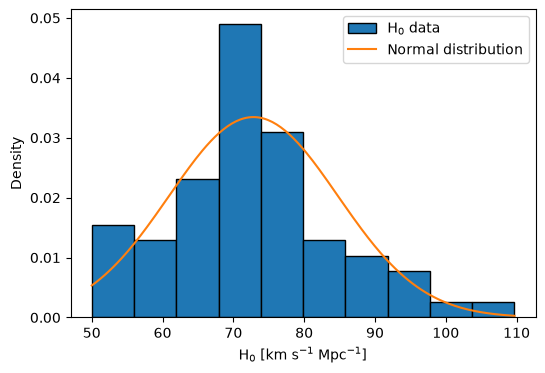

In [11]:
x = np.linspace(hubble2_df["h0"].min(), hubble2_df["h0"].max(), 200)

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(hubble2_df["h0"], density=True, edgecolor="black", label="H$_0$ data")
ax.plot(x, stats.norm.pdf(x, mean, sd), label="Normal distribution")

ax.set_xlabel("H$_0$ [km s$^{-1}$ Mpc$^{-1}$]")
ax.set_ylabel("Density")
ax.legend()
plt.show()

This histogram confirms that a normal distribution would be a poor fit. It also shows us more about the variability of the data. First, the density at the middle of the distribution is far greater than what the normal distribution predicts with a cluster of readings at about 70 km s⁻¹ Mpc⁻¹. Furthermore, the density at both tails is above the normal distribution, this will inflate the SD. The right tail also extends further than the left tail, pulling the mean above the median.

This positive skew can also be quantified using stats.skew

In [12]:
print(f"The skew for the H₀ data is {round(stats.skew(hubble2_df["h0"]), 2)}")

The skew for the H₀ data is 0.44


A box plot can identify outliers, we will use this to calibrate the trimmed mean.

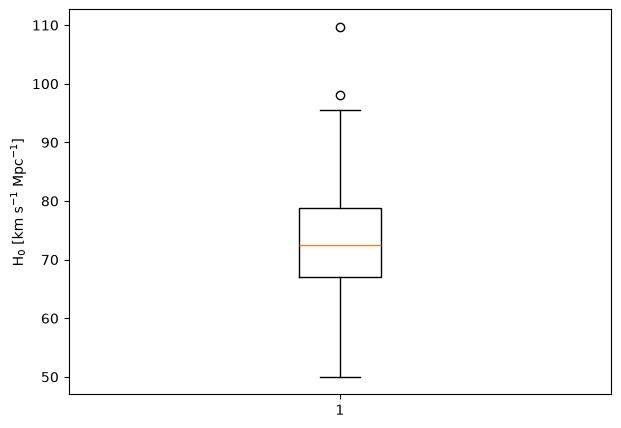

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot(hubble2_df["h0"])

ax.set_ylabel("H$_0$ [km s$^{-1}$ Mpc$^{-1}$]")
plt.show()

The plot shows that the two largest H₀ values are both outliers. The data will then be trimmed symmetrically to remove these points and to avoid skewing the data. These two points are:

In [14]:
print(hubble2_df.sort_values(by=["h0"], ascending=False).iloc[0:2])

       h0     date                                             source  \
62  109.7  2000.00                                         Abell S639   
16   98.0  1996.96  Grogin, N. \& Narayan, R. 1996, ApJ 473, 570 (...   

    valid_date  
62       False  
16        True  


The trimmed mean will be calculated by removing the top and bottom 2 values before calculating. This does lose two non-outlier data points but this is to prevent skew.

In [15]:
trimmed_h0 = np.sort(hubble2_df["h0"].values)[2:-2]

reference_h0 = trimmed_h0.mean()


To estimate the precision of this H₀ value, a standard error is needed. The usual SE = σ/√n formula doesn't apply to a trimmed mean as by removing the tails we underestimate the SD. Instead a bootstrap can be used. This is a process by which the dataset is resampled from the trimmed sample with replacement many times. The mean is recalculated each time and we can use the variance of these means to calculate a SD which can be used to calculate the SE. This method works regardless of the distribution of the data.

In [16]:
rng = np.random.default_rng(67)
h0_data = hubble2_df["h0"].values

samples = rng.choice(h0_data, size=(10000, len(h0_data)), replace=True) # Creating 10,000 samples the same length as the original dataset
boot_means = np.sort(samples, axis=1)[:, 2:-2].mean(axis=1) # This function orders each of those samples and then removes the two biggest and two smallest data points as we did for the mean

reference_h0_se = boot_means.std(ddof=1) 

print(f"Trimmed mean H₀ = {reference_h0:.2f} ± {reference_h0_se:.2f} km s⁻¹ Mpc⁻¹")

Trimmed mean H₀ = 72.54 ± 1.48 km s⁻¹ Mpc⁻¹


# 3. Data Comparison

## Methodology:

With a reference H₀ established it is now possible to compare it with the estimates from Part A. This comparison will be performed in two parts:

1. The first test is to see whether the Part A values are tpyical of the reference dataset. This involves determining the percentile of these estimates within the dataset and through calculating the number of standard deviations the estimate is from the mean.

2. The second test will be to determine if the standard errors of the estimates and the reference agree. This is to evaluate whether the gap between the two values can be explained by random error.

Importing the data from Part A

In [17]:
hubble1_df = pd.read_csv("data/26Ex_Hubble1_Cleaned.csv")
hubble1_results = pd.read_csv("data/Hubble1_Results.csv")

hubble1_results

,subset,H0,se,r2,rmse
0,all,79.06,0.34,0.997,1593.34
1,ngc,71.62,1.90,0.973,237.33
2,ngc_trimmed,73.77,3.77,0.734,240.05


### Test 1

In [18]:
for subset, h0, se in zip(hubble1_results["subset"], hubble1_results["H0"], hubble1_results["se"]):
    percentile = stats.percentileofscore(hubble2_df["h0"], h0)
    distance_from_ref = h0 - reference_h0
    n_sd = distance_from_ref / sd

    print(f"{subset}: H₀ = {h0:.2f} ± {se:.2f}, percentile = {percentile:.0f}, σ from reference = {n_sd:.2f}")

all: H₀ = 79.06 ± 0.34, percentile = 77, σ from reference = 0.55
ngc: H₀ = 71.62 ± 1.90, percentile = 48, σ from reference = -0.08
ngc_trimmed: H₀ = 73.77 ± 3.77, percentile = 60, σ from reference = 0.10


* All data: At the 77th percentile this is typical of the reference data. Although it lies above Q3 (78.8), it is only 0.55σ from the reference value, so it is still typical of the dataset.
* NGC: This value is closest to the reference of the three, being at the 48th percentile and only 0.08σ below the reference.
* Trimmed NGC: This value is also close to the centre. At the 60th percentile and 0.10σ from the reference it is only slightly further away than the untrimmed variant.

Overall, all three of these estimates seem typical of data within the reference dataset.

### Test 2

The SE comparisons will be displayed visually.

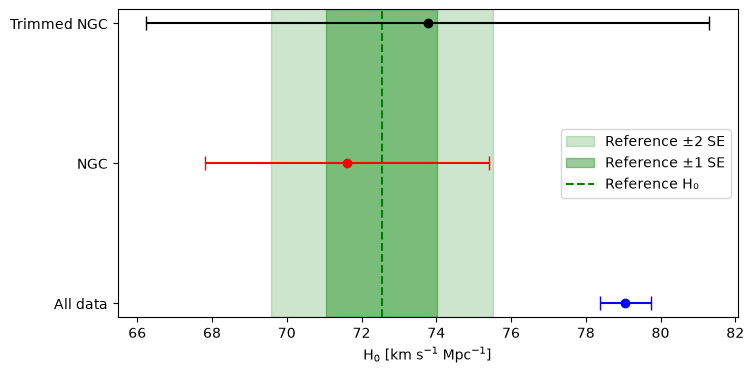

In [19]:
labels = {"all": "All data", "ngc": "NGC", "ngc_trimmed": "Trimmed NGC"}
colours = {"all": "blue", "ngc": "red", "ngc_trimmed": "black"}

fig, ax = plt.subplots(figsize=(8, 4))

ax.axvspan(reference_h0 - 2 * reference_h0_se, reference_h0 + 2 * reference_h0_se, color="green", alpha=0.2, label="Reference ±2 SE")
ax.axvspan(reference_h0 - reference_h0_se, reference_h0 + reference_h0_se, color="green", alpha=0.4, label="Reference ±1 SE")
ax.axvline(reference_h0, color="green", linestyle="--", label="Reference H₀")

for i, (subset, h0, se) in enumerate(zip(hubble1_results["subset"], hubble1_results["H0"], hubble1_results["se"])):
    ax.errorbar(h0, i, xerr=2*se, fmt="o", capsize=5, color=colours[subset])

ax.set_yticks(range(len(hubble1_results)), [labels[s] for s in hubble1_results["subset"]])
ax.set_xlabel("H$_0$ [km s$^{-1}$ Mpc$^{-1}$]")
ax.legend(loc="right")
plt.show()

1. All data: This reading does not fall within 2 SE of the reference value. This suggests that the gap between it and the reference is not merely due to random variation. Furthermore, its error bars are far smaller than those of the reference. Given that the reference data point draws from 65 full H0 readings instead of one, this should make us consider whether the SE for this reading may be an underestimate.

2. NGC: Its error bars overlap with the reference data point and its 1 SE error bands. This value agrees with the reference. 

3. NGC Trimmed: This data point also agrees with the reference for the same reasoning as for the NGC value. Its error bars are larger than for the untrimmed value, the reasoning for this was discussed in Part A.

These SE tests can be quantified further by calculating their Z scores (a measure of the probability of the given random variance)

In [20]:
for subset, h0, se in zip(hubble1_results["subset"], hubble1_results["H0"], hubble1_results["se"]):
    combined_se = np.sqrt(se**2 + reference_h0_se**2)
    z = (h0 - reference_h0) / combined_se

    print(f"{subset}: z = {z:.2f}")

all: z = 4.28
ngc: z = -0.38
ngc_trimmed: z = 0.30


Both the ngc values fall within 1z and can hence be explained by random variance. The all dataset having a z scored above 4 SDs suggests that it is overwhelmingly unlikely that this variance is due to randomness (only a 0.000934% chance).